**Dataset Link:** [Assignment-02 Datasets](https://drive.google.com/drive/folders/your_folder_id)

---

## Objective
This assignment aims to develop a practical understanding of:
- Creation of GeoDataFrames
- Appropriate visualisation selection  
- Critical evaluation of map-based visual designs

---

In [ ]:
!pip install geopandas folium mapclassify contextily -q

In [ ]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
from shapely.geometry import Point, LineString
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-darkgrid')
print("✓ Libraries imported successfully")

✓ Libraries imported successfully


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

BASE_PATH = '/content/drive/MyDrive/Assignment_02_Datasets/'
print(f"✓ Drive mounted. Dataset path: {BASE_PATH}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✓ Drive mounted. Dataset path: /content/drive/MyDrive/Assignment_02_Datasets/


---
# Problem 1: Bird Migration Analysis

**Tasks:**
1. Read the dataset into a pandas DataFrame
2. Convert to GeoDataFrame using latitude and longitude
3. Plot geographical region covered
4. Draw migration routes for each bird using line geometries

### Reading the Dataset

In [ ]:
bird_df = pd.read_csv(BASE_PATH + 'bird_migration.csv')

print("Bird Migration Dataset Info:")
print(f"Shape: {bird_df.shape}")
print(f"\nColumns: {bird_df.columns.tolist()}")
print(f"\nFirst 5 rows:")
bird_df.head()

Bird Migration Dataset Info:
Shape: (61920, 9)

Columns: ['Unnamed: 0', 'altitude', 'date_time', 'device_info_serial', 'direction', 'latitude', 'longitude', 'speed_2d', 'bird_name']

First 5 rows:


,Unnamed: 0,altitude,date_time,device_info_serial,direction,latitude,longitude,speed_2d,bird_name
0,0,71,2013-08-15 00:18:08+00,851,-150.469753,49.419860,2.120733,0.150000,Eric
1,1,68,2013-08-15 00:48:07+00,851,-136.151141,49.419880,2.120746,2.438360,Eric
2,2,68,2013-08-15 01:17:58+00,851,160.797477,49.420310,2.120885,0.596657,Eric
3,3,73,2013-08-15 01:47:51+00,851,32.769360,49.420359,2.120859,0.310161,Eric
4,4,69,2013-08-15 02:17:42+00,851,45.191230,49.420331,2.120887,0.193132,Eric


### Creating GeoDataFrame

In [ ]:
geometry = [Point(xy) for xy in zip(bird_df['longitude'], bird_df['latitude'])]

bird_gdf = gpd.GeoDataFrame(bird_df, geometry=geometry, crs='EPSG:4326')

print("✓ GeoDataFrame created successfully!")
print(f"CRS: {bird_gdf.crs}")
print(f"\nSpatial Extent:")
bounds = bird_gdf.total_bounds
print(f"  Longitude: [{bounds[0]:.4f}, {bounds[2]:.4f}]")
print(f"  Latitude: [{bounds[1]:.4f}, {bounds[3]:.4f}]")
bird_gdf.head()

✓ GeoDataFrame created successfully!
CRS: EPSG:4326

Spatial Extent:
  Longitude: [-17.6261, 4.8576]
  Latitude: [12.3544, 51.5185]


,Unnamed: 0,altitude,date_time,device_info_serial,direction,latitude,longitude,speed_2d,bird_name,geometry
0,0,71,2013-08-15 00:18:08+00,851,-150.469753,49.419860,2.120733,0.150000,Eric,POINT (2.12073 49.41986)
1,1,68,2013-08-15 00:48:07+00,851,-136.151141,49.419880,2.120746,2.438360,Eric,POINT (2.12075 49.41988)
2,2,68,2013-08-15 01:17:58+00,851,160.797477,49.420310,2.120885,0.596657,Eric,POINT (2.12088 49.42031)
3,3,73,2013-08-15 01:47:51+00,851,32.769360,49.420359,2.120859,0.310161,Eric,POINT (2.12086 49.42036)
4,4,69,2013-08-15 02:17:42+00,851,45.191230,49.420331,2.120887,0.193132,Eric,POINT (2.12089 49.42033)


### Plotting Geographical Region

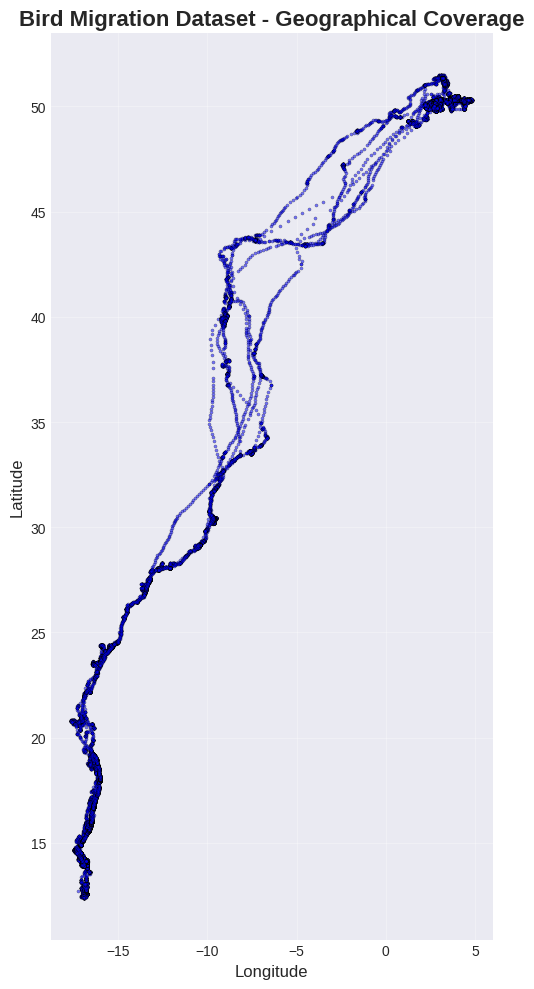

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(14, 10))

bird_gdf.plot(
    ax=ax,
    markersize=5,
    alpha=0.5,
    color='blue',
    edgecolor='black',
    linewidth=0.3
)

ax.set_title('Bird Migration Dataset - Geographical Coverage',
             fontsize=16, fontweight='bold')
ax.set_xlabel('Longitude', fontsize=12)
ax.set_ylabel('Latitude', fontsize=12)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Creating Migration Routes

In [ ]:
bird_routes = []

for bird_id in bird_df['bird_name'].unique():
    bird_data = bird_df[bird_df['bird_name'] == bird_id].copy()
    bird_data = bird_data.sort_values('date_time')

    coords = list(zip(bird_data['longitude'], bird_data['latitude']))

    if len(coords) >= 2:
        bird_routes.append({
            'bird_id': bird_id,
            'geometry': LineString(coords)
        })

routes_gdf = gpd.GeoDataFrame(bird_routes, crs='EPSG:4326')

print(f"✓ Created {len(routes_gdf)} bird migration routes")
routes_gdf.head()

✓ Created 3 bird migration routes


,bird_id,geometry
0,Eric,"LINESTRING (2.12073 49.41986, 2.12075 49.41988..."
1,Nico,"LINESTRING (4.39451 50.21345, 4.39401 50.21412..."
2,Sanne,"LINESTRING (2.28189 49.93106, 2.2819 49.93108,..."


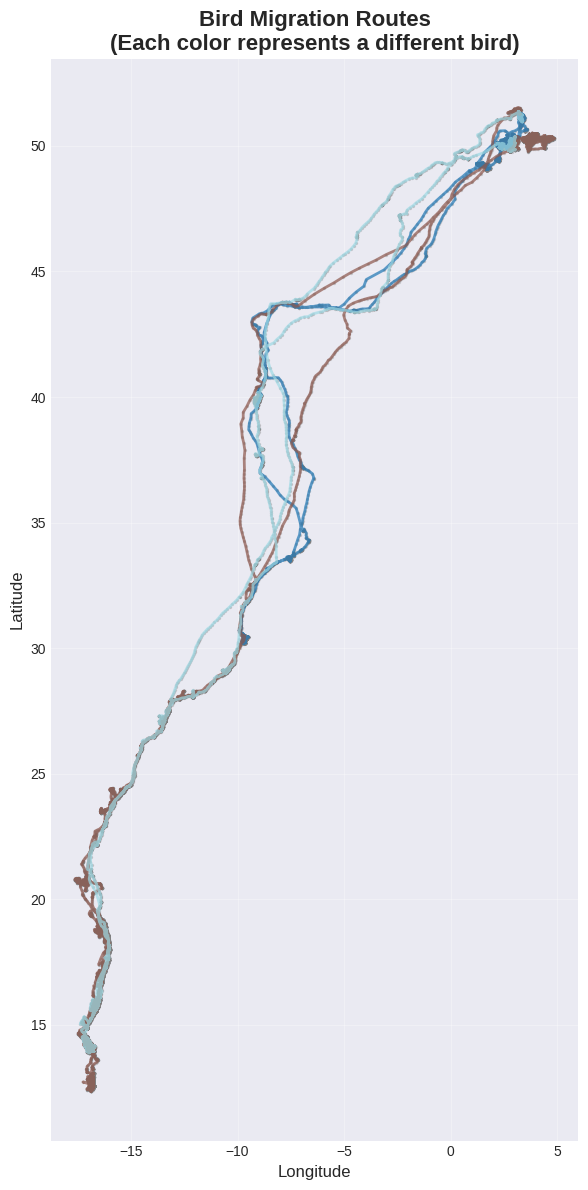

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(16, 12))

routes_gdf.plot(
    ax=ax,
    linewidth=2,
    alpha=0.7,
    cmap='tab20',
    legend=False
)

bird_gdf.plot(
    ax=ax,
    markersize=2,
    alpha=0.3,
    color='gray'
)

ax.set_title('Bird Migration Routes\n(Each color represents a different bird)',
             fontsize=16, fontweight='bold')
ax.set_xlabel('Longitude', fontsize=12)
ax.set_ylabel('Latitude', fontsize=12)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

---
# Problem 2: Landslide Distribution in India

**Tasks:**
1. Create GeoDataFrame for landslide locations
2. Visualize state-wise landslide occurrences across India

### Loading Landslide Data

In [ ]:
# Read global landslides dataset
landslide_df = pd.read_csv(BASE_PATH + 'globallandslides.csv')

print("Global Landslide Dataset:")
print(f"Total records: {len(landslide_df)}")
print(f"\nColumns: {landslide_df.columns.tolist()}")

# Filter for India
if 'country_name' in landslide_df.columns:
    india_landslides = landslide_df[landslide_df['country_name'] == 'India'].copy()
elif 'country' in landslide_df.columns:
    india_landslides = landslide_df[landslide_df['country'] == 'India'].copy()
else:
    india_landslides = landslide_df.copy()

print(f"\n✓ Landslides in India: {len(india_landslides)}")
india_landslides.head()

Global Landslide Dataset:
Total records: 11033

Columns: ['source_name', 'source_link', 'event_id', 'event_date', 'event_time', 'event_title', 'event_description', 'location_description', 'location_accuracy', 'landslide_category', 'landslide_trigger', 'landslide_size', 'landslide_setting', 'fatality_count', 'injury_count', 'storm_name', 'photo_link', 'notes', 'event_import_source', 'event_import_id', 'country_name', 'country_code', 'admin_division_name', 'admin_division_population', 'gazeteer_closest_point', 'gazeteer_distance', 'submitted_date', 'created_date', 'last_edited_date', 'longitude', 'latitude']

✓ Landslides in India: 1265


,source_name,source_link,event_id,event_date,event_time,event_title,event_description,location_description,location_accuracy,landslide_category,...,country_code,admin_division_name,admin_division_population,gazeteer_closest_point,gazeteer_distance,submitted_date,created_date,last_edited_date,longitude,latitude
32,One India,https://www.oneindia.com/2009/07/23/darjeeling...,1055,07/22/2009 12:00:00 AM,NaN,"Kerseong, West Bengal",The disruption of popular toy train services i...,"Kerseong, West Bengal",10km,landslide,...,IN,Bengal,46427.0,Kārsiyāng,0.15035,04/01/2014 12:00:00 AM,11/20/2017 03:17:00 PM,02/15/2018 03:51:00 PM,88.278800,26.882600
34,One India,https://www.oneindia.com/2009/07/23/darjeeling...,1054,07/22/2009 12:00:00 AM,NaN,"Gayabari, West Bengal",The disruption of popular toy train services i...,"Gayabari, West Bengal",10km,landslide,...,IN,Bengal,46427.0,Kārsiyāng,4.62496,04/01/2014 12:00:00 AM,11/20/2017 03:17:00 PM,02/15/2018 03:51:00 PM,88.314300,26.857200
45,Telegraph India,https://www.telegraphindia.com/1090707/jsp/sil...,1061,07/01/2009 05:40:00 AM,NaN,Bridge destroyed at 4th Mile,Landslides triggered by heavy rains hit an iro...,"4th Mile, Lower Mangshila in North Sikkim",1km,landslide,...,IN,NaN,1464.0,Mangan,3.54100,04/01/2014 12:00:00 AM,11/20/2017 03:17:00 PM,02/15/2018 03:51:00 PM,88.527000,27.478000
59,E-Pao,http://www.e-pao.net/GP.asp?src=28..210810.aug10,2164,07/29/2010 11:00:00 PM,NaN,"Chingai-Kuingai(Quingai) route (16 kms), Ching...",Since the Chingai-Quingai road has been sunk d...,"Chingai-Kuingai(Quingai) route (16 kms), Ching...",25km,landslide,...,IN,Manipur,15118.0,Phek,39.51186,04/01/2014 12:00:00 AM,11/20/2017 03:17:00 PM,02/15/2018 03:51:00 PM,94.482147,25.309863
62,ibnlive.in,http://ibnlive.in.com/generalnewsfeed/news/two...,3821,07/21/2011 12:00:00 AM,NaN,"Kumaon, Uttarakhand","Dehradun, July 21 (PTI) Two persons were kille...","Kumaon, Uttarakhand",25km,landslide,...,IN,Uttarakhand,32442.0,Almora,15.27100,04/01/2014 12:00:00 AM,11/20/2017 03:17:00 PM,02/15/2018 03:51:00 PM,79.636700,29.733400


### Creating Landslide GeoDataFrame

In [ ]:
# Create Point geometries
landslide_geometry = [Point(xy) for xy in zip(
    india_landslides['longitude'],
    india_landslides['latitude']
)]

# Create GeoDataFrame
landslide_gdf = gpd.GeoDataFrame(
    india_landslides,
    geometry=landslide_geometry,
    crs='EPSG:4326'
)

print("✓ Landslide GeoDataFrame created")
print(f"Total points: {len(landslide_gdf)}")
landslide_gdf.head()

✓ Landslide GeoDataFrame created
Total points: 1265


,source_name,source_link,event_id,event_date,event_time,event_title,event_description,location_description,location_accuracy,landslide_category,...,admin_division_name,admin_division_population,gazeteer_closest_point,gazeteer_distance,submitted_date,created_date,last_edited_date,longitude,latitude,geometry
32,One India,https://www.oneindia.com/2009/07/23/darjeeling...,1055,07/22/2009 12:00:00 AM,NaN,"Kerseong, West Bengal",The disruption of popular toy train services i...,"Kerseong, West Bengal",10km,landslide,...,Bengal,46427.0,Kārsiyāng,0.15035,04/01/2014 12:00:00 AM,11/20/2017 03:17:00 PM,02/15/2018 03:51:00 PM,88.278800,26.882600,POINT (88.2788 26.8826)
34,One India,https://www.oneindia.com/2009/07/23/darjeeling...,1054,07/22/2009 12:00:00 AM,NaN,"Gayabari, West Bengal",The disruption of popular toy train services i...,"Gayabari, West Bengal",10km,landslide,...,Bengal,46427.0,Kārsiyāng,4.62496,04/01/2014 12:00:00 AM,11/20/2017 03:17:00 PM,02/15/2018 03:51:00 PM,88.314300,26.857200,POINT (88.3143 26.8572)
45,Telegraph India,https://www.telegraphindia.com/1090707/jsp/sil...,1061,07/01/2009 05:40:00 AM,NaN,Bridge destroyed at 4th Mile,Landslides triggered by heavy rains hit an iro...,"4th Mile, Lower Mangshila in North Sikkim",1km,landslide,...,NaN,1464.0,Mangan,3.54100,04/01/2014 12:00:00 AM,11/20/2017 03:17:00 PM,02/15/2018 03:51:00 PM,88.527000,27.478000,POINT (88.527 27.478)
59,E-Pao,http://www.e-pao.net/GP.asp?src=28..210810.aug10,2164,07/29/2010 11:00:00 PM,NaN,"Chingai-Kuingai(Quingai) route (16 kms), Ching...",Since the Chingai-Quingai road has been sunk d...,"Chingai-Kuingai(Quingai) route (16 kms), Ching...",25km,landslide,...,Manipur,15118.0,Phek,39.51186,04/01/2014 12:00:00 AM,11/20/2017 03:17:00 PM,02/15/2018 03:51:00 PM,94.482147,25.309863,POINT (94.48215 25.30986)
62,ibnlive.in,http://ibnlive.in.com/generalnewsfeed/news/two...,3821,07/21/2011 12:00:00 AM,NaN,"Kumaon, Uttarakhand","Dehradun, July 21 (PTI) Two persons were kille...","Kumaon, Uttarakhand",25km,landslide,...,Uttarakhand,32442.0,Almora,15.27100,04/01/2014 12:00:00 AM,11/20/2017 03:17:00 PM,02/15/2018 03:51:00 PM,79.636700,29.733400,POINT (79.6367 29.7334)


### Loading India State Boundaries

In [ ]:
# Load India state boundary shapefile
india_states = gpd.read_file(BASE_PATH + 'India_State_Boundary.shp')

india_states = india_states.set_crs('EPSG:4326', allow_override=True)

print("India State Boundaries:")
print(f"Total states: {len(india_states)}")
print(f"\nColumns: {india_states.columns.tolist()}")
india_states.head()

India State Boundaries:
Total states: 37

Columns: ['State_Name', 'geometry']


,State_Name,geometry
0,Andaman & Nicobar,"MULTIPOLYGON (((10341718.474 1449533.1605, 103..."
1,Chandigarh,"POLYGON ((8546255.6161 3606050.8131, 8546315.4..."
2,Daman and Diu and Dadra and Nagar Haveli,"MULTIPOLYGON (((8122247.8221 2312434.407, 8122..."
3,Delhi,"POLYGON ((8583390.5697 3359116.1901, 8583476.2..."
4,Haryana,"POLYGON ((8524318.5392 3516490.8645, 8524451.3..."


### Spatial Joinning and Count

In [ ]:
# Check the actual CRS of the shapefile
print("Original india_states CRS:", india_states.crs)
print("Original bounds:", india_states.total_bounds)


india_states_original = india_states.copy()

if india_states.total_bounds[0] > 1000:  # If coordinates are in meters
    print("\n  Shapefile is in projected coordinates (meters), not EPSG:4326!")
    print("Converting to EPSG:4326...")

    # Set the actual CRS (Web Mercator)
    india_states.crs = 'EPSG:3857'

    # Now convert to WGS84
    india_states = india_states.to_crs('EPSG:4326')

    print("✓ Converted to EPSG:4326")
    print("New bounds:", india_states.total_bounds)

# Now perform spatial join
landslides_with_state = gpd.sjoin(
    landslide_gdf,
    india_states,
    how='left',
    predicate='within'
)

print(f"\nLandslides matched to states: {landslides_with_state['State_Name'].notna().sum()}")

# Count landslides per state
state_landslide_count = landslides_with_state.groupby('State_Name').size().reset_index(name='landslide_count')

print("\nState-wise Landslide Count:")
print(state_landslide_count.sort_values('landslide_count', ascending=False))

# Merge with states
india_states_with_count = india_states.merge(
    state_landslide_count,
    on='State_Name',
    how='left'
).fillna({'landslide_count': 0})

print(f"\n✓ Merged state boundaries with landslide counts")
print(f"States with landslides: {(india_states_with_count['landslide_count'] > 0).sum()}")

Original india_states CRS: EPSG:4326
Original bounds: [ 7583508.4975       753607.8429     10843390.738       4452637.58875181]

  Shapefile is in projected coordinates (meters), not EPSG:4326!
Converting to EPSG:4326...
✓ Converted to EPSG:4326
New bounds: [68.12381591  6.75407754 97.40783632 37.09701157]

Landslides matched to states: 1263

State-wise Landslide Count:
           State_Name  landslide_count
27        Uttarakhand              188
9   Jammu and Kashmir              181
8    Himachal Pradesh              151
16            Manipur               79
28        West Bengal               75
15        Maharashtra               71
2               Assam               69
19           Nagaland               69
12             Kerala               53
22             Sikkim               47
1   Arunachal Pradesh               44
23          Tamilnadu               37
11          Karnataka               31
17          Meghalaya               30
18            Mizoram               26
5  

### Visualizing State-wise Distribution

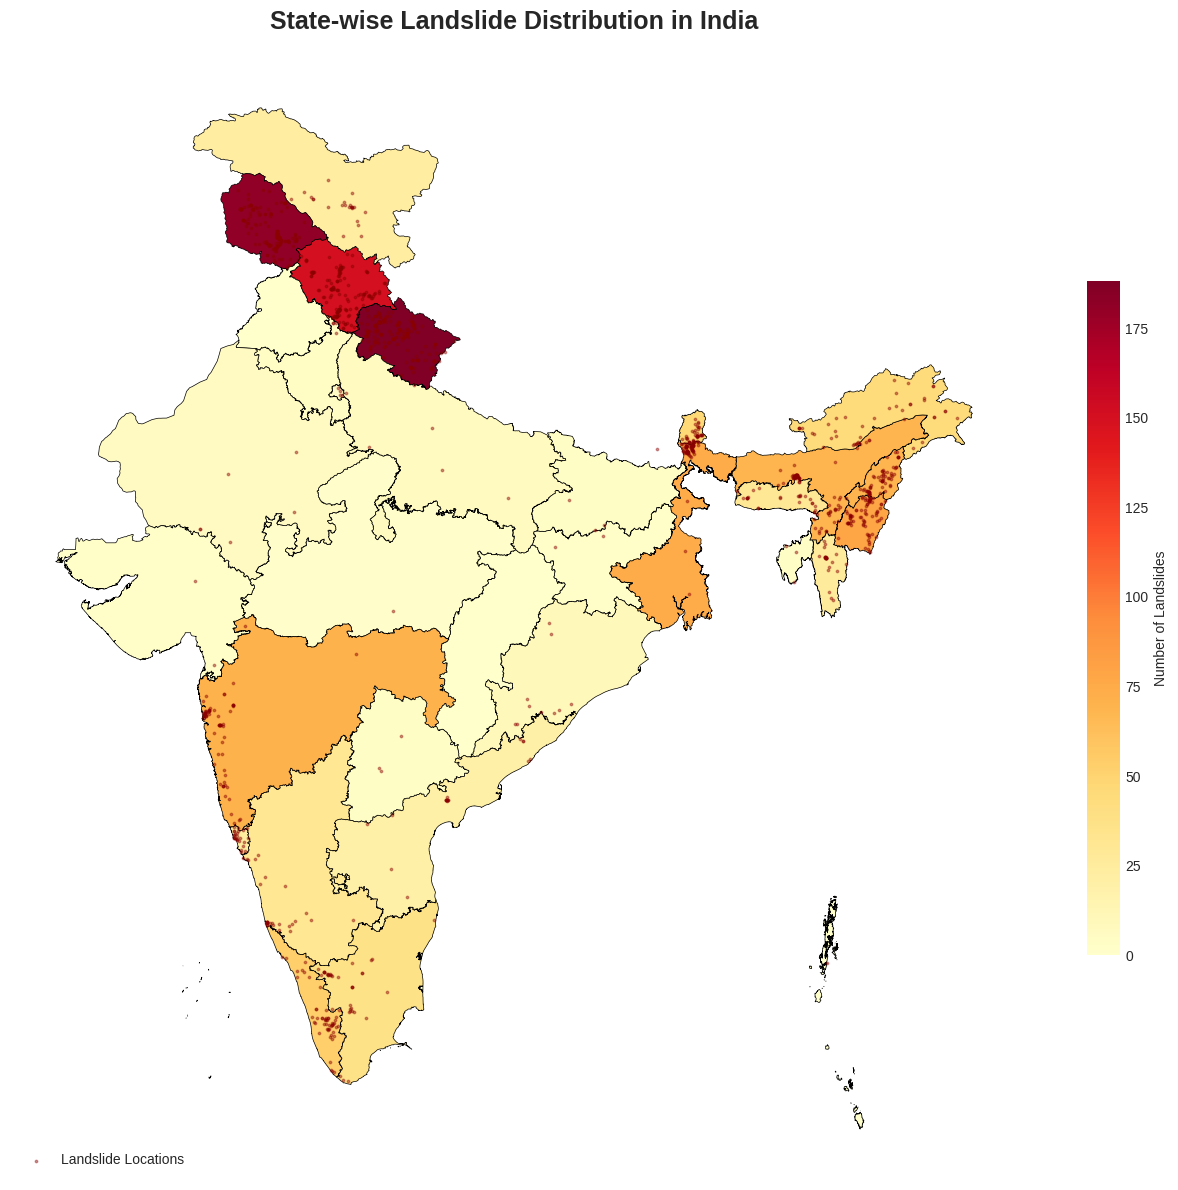

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(14, 12))

# Choropleth map
india_states_with_count.plot(
    column='landslide_count',
    ax=ax,
    legend=True,
    cmap='YlOrRd',
    edgecolor='black',
    linewidth=0.5,
    legend_kwds={
        'label': 'Number of Landslides',
        'orientation': 'vertical',
        'shrink': 0.6
    }
)

# Plot landslide points
landslide_gdf.plot(
    ax=ax,
    markersize=3,
    color='darkred',
    alpha=0.4,
    label='Landslide Locations'
)

ax.set_title('State-wise Landslide Distribution in India',
             fontsize=18, fontweight='bold', pad=20)
ax.legend(loc='lower left')
ax.set_axis_off()

plt.tight_layout()
plt.show()

---
# Problem 3: State-Level Landslide Analysis

**Roll Number:** B23CM1044 (Last digit: **4** - EVEN)  
**State:** **Himachal Pradesh**

**Task:** Create district-wise landslide map for Himachal Pradesh

### Loading District Data

In [ ]:
district_data = pd.read_csv(BASE_PATH + 'district wise lat and long.csv')

# Filter for Himachal Pradesh
hp_districts = district_data[district_data['State'] == 'Himachal Pradesh'].copy()

print(f" Districts in Himachal Pradesh: {len(hp_districts)}")
hp_districts

 Districts in Himachal Pradesh: 11


,State,District,Latitude,Longitude,Population in 2001,Population in 2011
130,Himachal Pradesh,Bilaspur,31.378042,76.653161,340885,381956
131,Himachal Pradesh,Chamba,32.667418,76.393541,460887,519080
132,Himachal Pradesh,Hamirpur,31.676685,76.497671,412700,454768
133,Himachal Pradesh,Kangra,32.140936,76.412059,1339030,1510075
134,Himachal Pradesh,Kinnaur,31.606672,78.516137,78334,84121
135,Himachal Pradesh,Kullu,31.909119,77.409226,381571,437903
136,Himachal Pradesh,Mandi,31.635806,76.965569,901344,999777
137,Himachal Pradesh,Shimla,31.155725,77.625730,722502,814010
138,Himachal Pradesh,Sirmaur,30.682764,77.431847,458593,529855
139,Himachal Pradesh,Solan,31.038643,76.944421,500557,580320


### Creating District GeoDataFrame

In [ ]:
# Create Point geometries for district centroids
hp_geometry = [Point(xy) for xy in zip(
    hp_districts['Longitude'],
    hp_districts['Latitude']
)]

hp_districts_gdf = gpd.GeoDataFrame(
    hp_districts,
    geometry=hp_geometry,
    crs='EPSG:4326'
)

print(" HP Districts GeoDataFrame created")
hp_districts_gdf.head()

 HP Districts GeoDataFrame created


,State,District,Latitude,Longitude,Population in 2001,Population in 2011,geometry
130,Himachal Pradesh,Bilaspur,31.378042,76.653161,340885,381956,POINT (76.65316 31.37804)
131,Himachal Pradesh,Chamba,32.667418,76.393541,460887,519080,POINT (76.39354 32.66742)
132,Himachal Pradesh,Hamirpur,31.676685,76.497671,412700,454768,POINT (76.49767 31.67668)
133,Himachal Pradesh,Kangra,32.140936,76.412059,1339030,1510075,POINT (76.41206 32.14094)
134,Himachal Pradesh,Kinnaur,31.606672,78.516137,78334,84121,POINT (78.51614 31.60667)


### Filtering Landslides for Himachal Pradesh

In [ ]:
# HP boundary
hp_boundary = india_states[india_states['State_Name'] == 'Himachal Pradesh']

if len(hp_boundary) > 0:
    hp_landslides = gpd.sjoin(
        landslide_gdf,
        hp_boundary,
        how='inner',
        predicate='within'
    )
else:
    hp_bounds = hp_districts_gdf.total_bounds
    hp_landslides = landslide_gdf[
        (landslide_gdf.geometry.x >= hp_bounds[0] - 0.5) &
        (landslide_gdf.geometry.x <= hp_bounds[2] + 0.5) &
        (landslide_gdf.geometry.y >= hp_bounds[1] - 0.5) &
        (landslide_gdf.geometry.y <= hp_bounds[3] + 0.5)
    ]

print(f" Landslides in Himachal Pradesh: {len(hp_landslides)}")

 Landslides in Himachal Pradesh: 151


### Assigning to Nearest District

In [ ]:
from scipy.spatial import cKDTree

# Get coordinates
district_coords = np.array(list(zip(
    hp_districts_gdf.geometry.x,
    hp_districts_gdf.geometry.y
)))

if len(hp_landslides) > 0:
    landslide_coords = np.array(list(zip(
        hp_landslides.geometry.x,
        hp_landslides.geometry.y
    )))

    # Find nearest district using KD-Tree
    tree = cKDTree(district_coords)
    distances, indices = tree.query(landslide_coords)

    hp_landslides['nearest_district'] = hp_districts_gdf.iloc[indices]['District'].values

    # Count per district
    district_landslide_count = hp_landslides.groupby('nearest_district').size().reset_index(name='landslide_count')
else:
    district_landslide_count = pd.DataFrame({
        'nearest_district': hp_districts_gdf['District'].values,
        'landslide_count': 0
    })

# Merge with districts
hp_districts_with_count = hp_districts_gdf.merge(
    district_landslide_count,
    left_on='District',
    right_on='nearest_district',
    how='left'
).fillna(0)

print("\nDistrict-wise Landslide Count:")
print(hp_districts_with_count[['District', 'landslide_count']].sort_values('landslide_count', ascending=False))


District-wise Landslide Count:
    District  landslide_count
5      Kullu             34.0
9      Solan             32.0
6      Mandi             22.0
7     Shimla             16.0
4    Kinnaur             16.0
8    Sirmaur             10.0
3     Kangra             10.0
1     Chamba              6.0
0   Bilaspur              3.0
2   Hamirpur              2.0
10       Una              0.0


### Visualizing District-wise Map

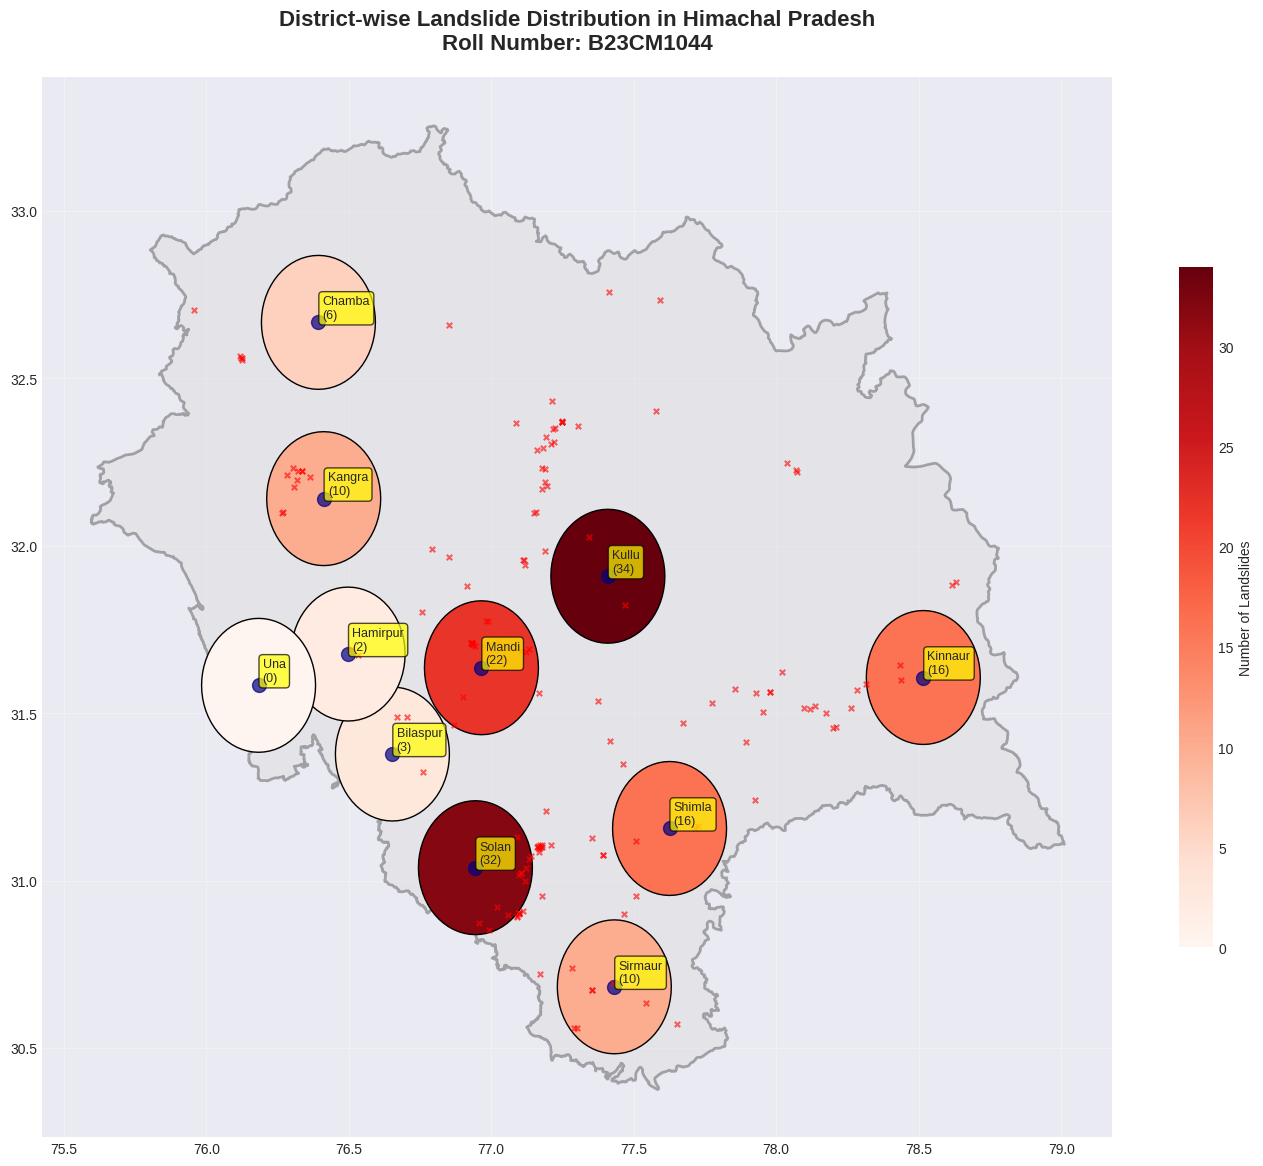

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(14, 12))

# Plot HP boundary
if len(hp_boundary) > 0:
    hp_boundary.plot(
        ax=ax,
        facecolor='lightgray',
        edgecolor='black',
        linewidth=2,
        alpha=0.3
    )

# Create buffer zones for visualization
hp_districts_with_count['buffer'] = hp_districts_with_count.geometry.buffer(0.2)
hp_districts_buffered = hp_districts_with_count.set_geometry('buffer')

# Plot districts with count
hp_districts_buffered.plot(
    column='landslide_count',
    ax=ax,
    cmap='Reds',
    edgecolor='black',
    linewidth=1,
    legend=True,
    legend_kwds={'label': 'Number of Landslides', 'shrink': 0.6}
)

# Plot centroids
hp_districts_with_count.plot(
    ax=ax,
    color='navy',
    markersize=100,
    alpha=0.7
)

# Plot landslides
if len(hp_landslides) > 0:
    hp_landslides.plot(
        ax=ax,
        markersize=15,
        color='red',
        alpha=0.6,
        marker='x'
    )

# Add labels
for idx, row in hp_districts_with_count.iterrows():
    ax.annotate(
        text=f"{row['District']}\n({int(row['landslide_count'])})",
        xy=(row.geometry.x, row.geometry.y),
        xytext=(3, 3),
        textcoords='offset points',
        fontsize=9,
        bbox=dict(boxstyle='round,pad=0.3', facecolor='yellow', alpha=0.7)
    )

ax.set_title(
    'District-wise Landslide Distribution in Himachal Pradesh\nRoll Number: B23CM1044',
    fontsize=16, fontweight='bold', pad=20
)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

---
# Problem 4: US Election Vote Share Visualization

**Roll Number:** B23CM1044 (Last digit: **4** - EVEN)  
**Party:** **Democratic Party**

**Task:** Create map showing percentage of votes for the Democratic Party

### Loading Election Data

In [ ]:
# Read election data
election_df = pd.read_csv(BASE_PATH + 'democratic_vs_republican_votes_by_usa_state_2020.csv')

if 'democratic_percentage' not in election_df.columns:
    election_df['democratic_percentage'] = (
        election_df['DEM'] / (election_df['DEM'] + election_df['REP'])
    ) * 100

if 'republican_percentage' not in election_df.columns:
    election_df['republican_percentage'] = (
        election_df['REP'] / (election_df['DEM'] + election_df['REP'])
    ) * 100

print(" Election data loaded")
print(f"Total states: {len(election_df)}")
election_df.head()

 Election data loaded
Total states: 51


,state,DEM,REP,usa_state,usa_state_code,percent_democrat,democratic_percentage,republican_percentage
0,Alabama,843473,1434159,Alabama,AL,37.032892,37.032892,62.967108
1,Alaska,45758,80999,Alaska,AK,36.098993,36.098993,63.901007
2,Arizona,1643664,1626679,Arizona,AZ,50.259682,50.259682,49.740318
3,Arkansas,420985,761251,Arkansas,AR,35.609218,35.609218,64.390782
4,California,9315259,4812735,California,CA,65.934760,65.934760,34.065240


### Extracting and Load US State Boundaries

In [ ]:
import zipfile
import os

# Extract zip file
zip_path = BASE_PATH + 'usa.zip'
extract_path = BASE_PATH + 'usa_extracted/'

if not os.path.exists(extract_path):
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_path)
    print(" Extracted usa.zip")

# Find shapefiles
shp_files = []
for root, dirs, files in os.walk(extract_path):
    for file in files:
        if file.endswith('.shp'):
            shp_files.append(os.path.join(root, file))

print(f"Found {len(shp_files)} shapefile(s)")

# Load shapefile
for shp in shp_files:
    usa_states = gpd.read_file(shp)
    print(f"\nLoaded: {shp}")
    print(f"Records: {len(usa_states)}")
    if 30 < len(usa_states) < 70:
        break

print(f"\n Using shapefile with {len(usa_states)} states")
usa_states.head()

Found 1 shapefile(s)

Loaded: /content/drive/MyDrive/Assignment_02_Datasets/usa_extracted/s_18mr25.shp
Records: 59

 Using shapefile with 59 states


,STATE,NAME,FIPS,LON,LAT,geometry
0,AL,Alabama,01,-86.82676,32.79354,"MULTIPOLYGON (((-88.11011 30.25891, -88.10638 ..."
1,AR,Arkansas,05,-92.43920,34.89977,"POLYGON ((-91.62986 36.49921, -91.62849 36.499..."
2,AS,American Samoa,60,-170.37215,-14.26486,"MULTIPOLYGON (((-168.14924 -14.53377, -168.148..."
3,AZ,Arizona,04,-111.66457,34.29323,"POLYGON ((-110.4909 37.00361, -110.4875 37.002..."
4,CA,California,06,-119.60818,37.24537,"MULTIPOLYGON (((-118.4262 32.79973, -118.42634..."


### Merging Election Data with Boundaries

In [ ]:
# Identify state name columns
state_col_candidates = ['NAME', 'STUSPS', 'STATE_NAME', 'State', 'name']
state_col = next((col for col in state_col_candidates if col in usa_states.columns), usa_states.columns[0])

election_state_col = next((col for col in ['state', 'State', 'STATE'] if col in election_df.columns), election_df.columns[0])

print(f"State column in shapefile: {state_col}")
print(f"State column in election data: {election_state_col}")

# Standardize names
usa_states['state_name_clean'] = usa_states[state_col].str.upper().str.strip()
election_df['state_name_clean'] = election_df[election_state_col].str.upper().str.strip()

# Merge
usa_election = usa_states.merge(
    election_df,
    on='state_name_clean',
    how='left'
).fillna(0)

print(f"\n Merged data: {len(usa_election)} states")
print(f"States with election data: {usa_election['democratic_percentage'].gt(0).sum()}")

State column in shapefile: NAME
State column in election data: state

 Merged data: 59 states
States with election data: 51


### Visualizing Democratic Party Vote Share

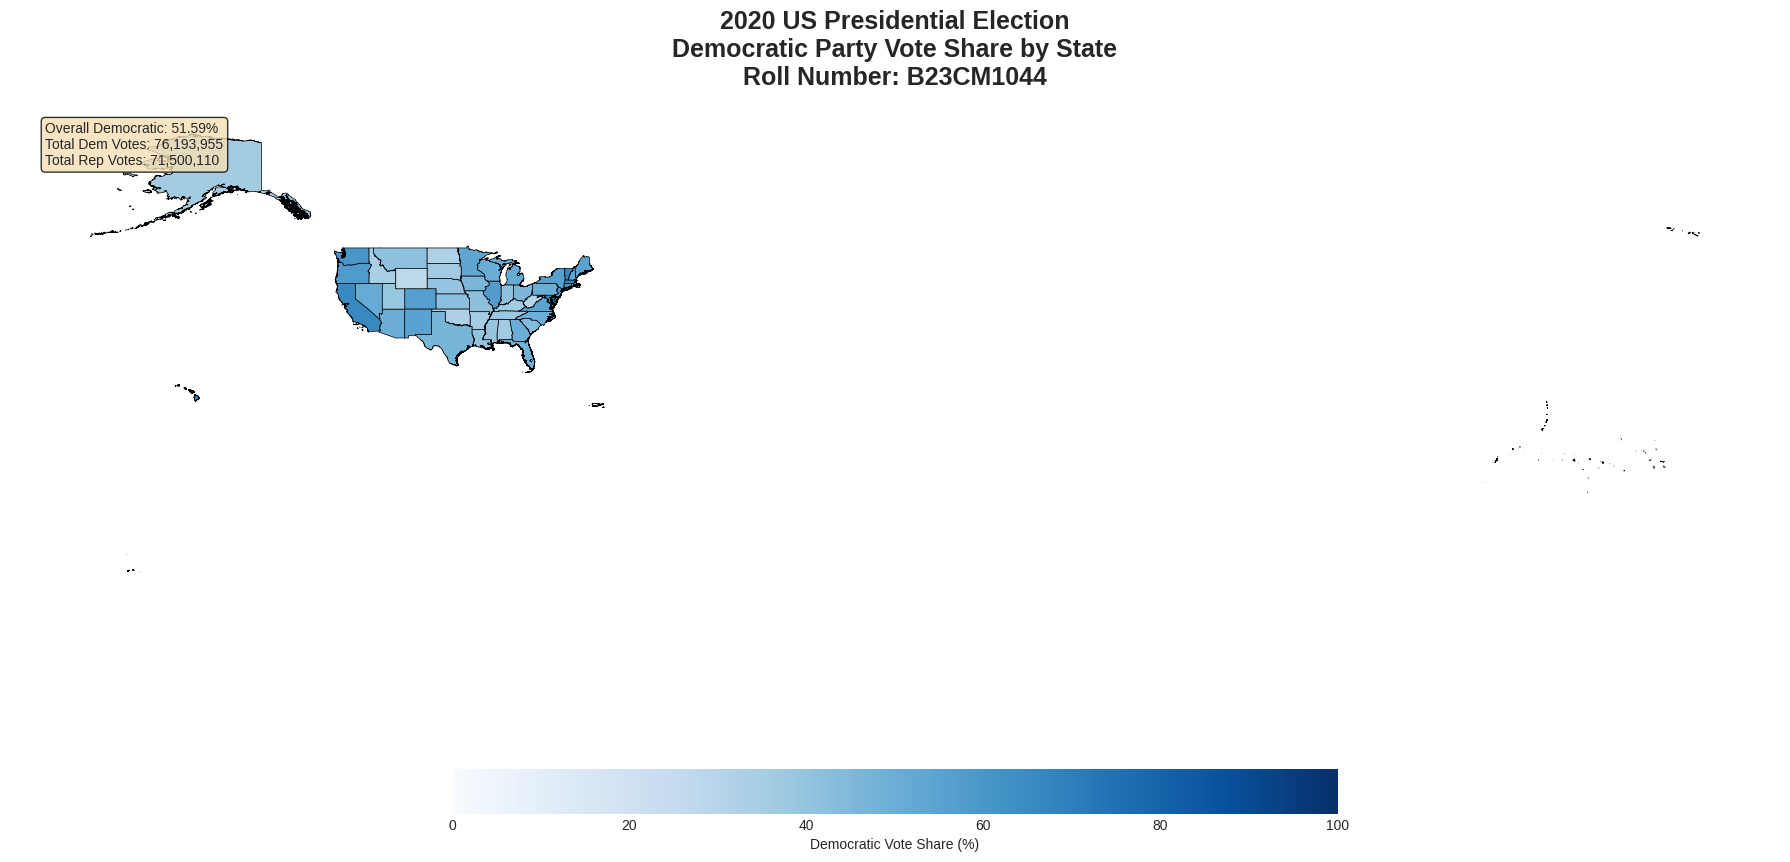

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(18, 12))

# Choropleth map
usa_election.plot(
    column='democratic_percentage',
    ax=ax,
    cmap='Blues',
    edgecolor='black',
    linewidth=0.5,
    legend=True,
    vmin=0,
    vmax=100,
    legend_kwds={
        'label': 'Democratic Vote Share (%)',
        'orientation': 'horizontal',
        'shrink': 0.5
    }
)

ax.set_title(
    '2020 US Presidential Election\nDemocratic Party Vote Share by State\nRoll Number: B23CM1044',
    fontsize=18, fontweight='bold', pad=20
)
ax.set_axis_off()

# Add statistics
total_dem = election_df['DEM'].sum()
total_rep = election_df['REP'].sum()
overall_pct = (total_dem / (total_dem + total_rep)) * 100

stats_text = f"Overall Democratic: {overall_pct:.2f}%\n"
stats_text += f"Total Dem Votes: {total_dem:,}\n"
stats_text += f"Total Rep Votes: {total_rep:,}"

ax.text(
    0.02, 0.98, stats_text,
    transform=ax.transAxes,
    fontsize=10,
    verticalalignment='top',
    bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8)
)

plt.tight_layout()
plt.show()

### Enhanced Visualization with Winners

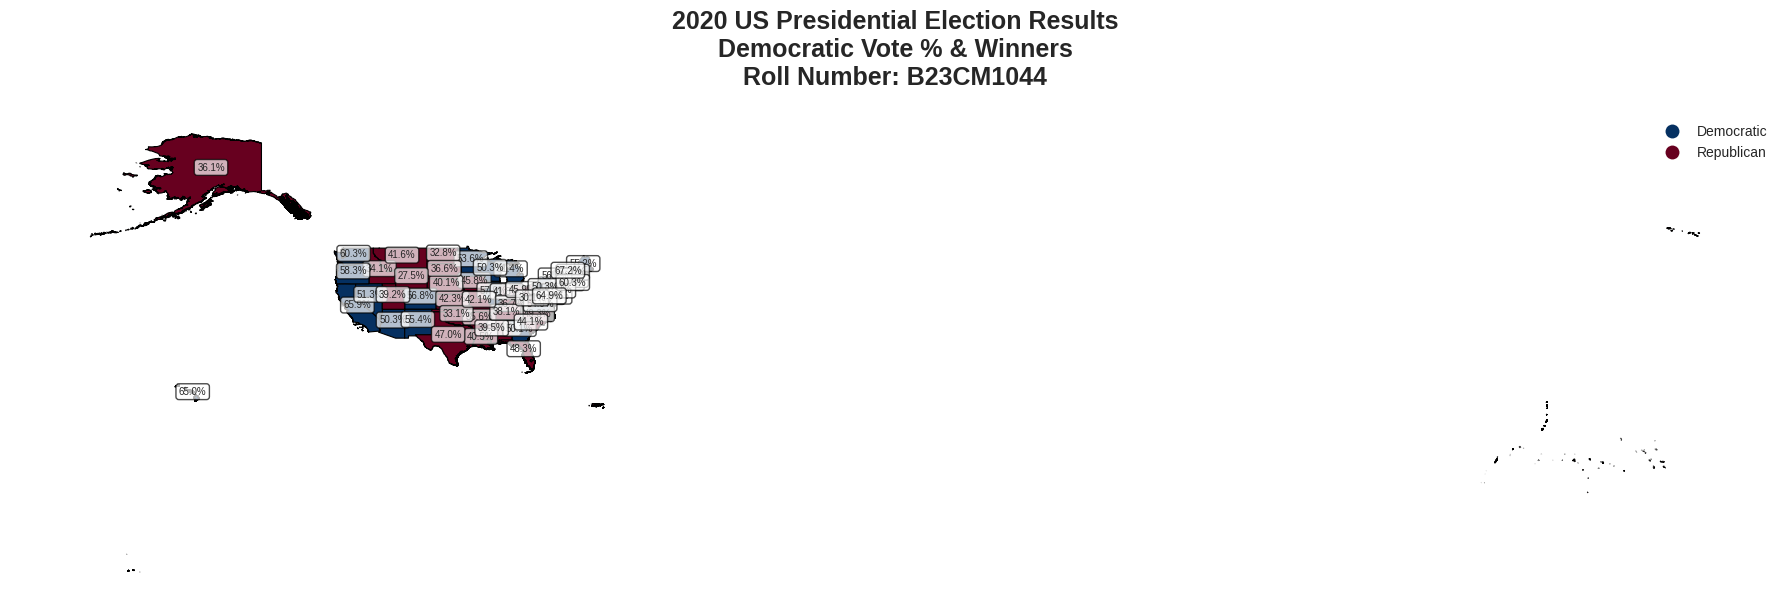


ELECTION SUMMARY
Democratic wins: 26
Republican wins: 33

Top 5 Democratic states:
                    NAME  democratic_percentage
7   District of Columbia              94.707520
44               Vermont              67.156182
18         Massachusetts              66.783356
4             California              65.934760
10                Hawaii              65.042567


In [ ]:
# Determine winner
usa_election['winner'] = usa_election.apply(
    lambda row: 'Democratic' if row['democratic_percentage'] > row['republican_percentage'] else 'Republican',
    axis=1
)

fig, ax = plt.subplots(1, 1, figsize=(18, 12))

# Plot with winner colors
usa_election.plot(
    column='winner',
    ax=ax,
    categorical=True,
    legend=True,
    cmap='RdBu_r',
    edgecolor='black',
    linewidth=0.8
)

# Add labels
for idx, row in usa_election.iterrows():
    if row.geometry and row['democratic_percentage'] > 0:
        centroid = row.geometry.centroid
        ax.annotate(
            text=f"{row['democratic_percentage']:.1f}%",
            xy=(centroid.x, centroid.y),
            ha='center',
            fontsize=7,
            bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.7)
        )

ax.set_title(
    '2020 US Presidential Election Results\nDemocratic Vote % & Winners\nRoll Number: B23CM1044',
    fontsize=18, fontweight='bold', pad=20
)
ax.set_axis_off()

plt.tight_layout()
plt.show()

# Print summary
print("\n" + "="*60)
print("ELECTION SUMMARY")
print("="*60)
print(f"Democratic wins: {(usa_election['winner'] == 'Democratic').sum()}")
print(f"Republican wins: {(usa_election['winner'] == 'Republican').sum()}")
print(f"\nTop 5 Democratic states:")
print(usa_election.nlargest(5, 'democratic_percentage')[[state_col, 'democratic_percentage']])